Q.1 In a liquid-phase rector the rection A+B=C reaches equilibrium. Initial concentration are [A].= 1.0, [B].=1.0 and [C].=0 mol/L. If x mol/L of C is
formed, Kc = x / (1-x)^2, which rearranges to the quadratic equation
Kc.x^2 - (2Kc + 1).x + Kc =0
(a) reads Kc using input(), prints the data type of the raw input and of the converted value, and shows a clear message (no crash) if the text is not
a number or if Kc <= 0;
(b) finds a, b, c, the discriminant and both roots;
(c) selects the physically meaningful root (0 <= x <= 1);
(d) print equilibrium [A], [B], [C] (3 decimals) and the conversion of the limiting reactant = x / [A]. * 100 (%);
(e) classifies the conversion using if / elif / else:>= 70% "High", >= 40% "Moderate", otherwise"Low".
Test with Kc =4, Kc = 0.5, Kc =abc and Kc=-2.

In [ ]:
import math
def solve_equilibrium(raw_input=None):
    """Read Kc, solve the equilibrium quadratic, and report the result."""
    if raw_input is None:
        raw_input = input("Enter Kc: ")

    print(f"Raw input type: {type(raw_input).__name__}")

    try:
        kc = float(raw_input)
    except (TypeError, ValueError):
        print("Invalid input: Kc must be a number.")
        return

    print(f"Converted value type: {type(kc).__name__}")

    if kc <= 0:
        print("Invalid input: Kc must be greater than 0.")
        return

    a = kc
    b = -(2 * kc + 1)
    c = kc
    discriminant = b**2 - 4 * a * c

    print(f"a = {a}, b = {b}, c = {c}")
    print(f"Discriminant = {discriminant}")

    if discriminant < 0:
        print("No real roots exist.")
        return

    root_1 = (-b + math.sqrt(discriminant)) / (2 * a)
    root_2 = (-b - math.sqrt(discriminant)) / (2 * a)
    print(f"Root 1 = {root_1}")
    print(f"Root 2 = {root_2}")

    physical_roots = [root for root in (root_1, root_2) if 0 <= root <= 1]
    if not physical_roots:
        print("No physically meaningful root was found.")
        return

    x = physical_roots[0]
    equilibrium_a = 1 - x
    equilibrium_b = 1 - x
    equilibrium_c = x
    conversion = x / 1.0 * 100

    if conversion >= 70:
        classification = "High"
    elif conversion >= 40:
        classification = "Moderate"
    else:
        classification = "Low"

    print(f"Physical root x = {x:.6f}")
    print(f"Equilibrium [A] = {equilibrium_a:.3f} mol/L")
    print(f"Equilibrium [B] = {equilibrium_b:.3f} mol/L")
    print(f"Equilibrium [C] = {equilibrium_c:.3f} mol/L")
    print(f"Limiting-reactant conversion = {conversion:.3f}%")
    print(f"Conversion classification: {classification}")


In [10]:
# Test cases requested in the question
for test_value in ("4", "0.5", "abc", "-2"):
    print(f"\n--- Testing Kc = {test_value} ---")
    solve_equilibrium(test_value)



--- Testing Kc = 4 ---
Raw input type: str
Converted value type: float
a = 4.0, b = -9.0, c = 4.0
Discriminant = 17.0
Root 1 = 1.6403882032022077
Root 2 = 0.6096117967977924
Physical root x = 0.609612
Equilibrium [A] = 0.390 mol/L
Equilibrium [B] = 0.390 mol/L
Equilibrium [C] = 0.610 mol/L
Limiting-reactant conversion = 60.961%
Conversion classification: Moderate

--- Testing Kc = 0.5 ---
Raw input type: str
Converted value type: float
a = 0.5, b = -2.0, c = 0.5
Discriminant = 3.0
Root 1 = 3.732050807568877
Root 2 = 0.2679491924311228
Physical root x = 0.267949
Equilibrium [A] = 0.732 mol/L
Equilibrium [B] = 0.732 mol/L
Equilibrium [C] = 0.268 mol/L
Limiting-reactant conversion = 26.795%
Conversion classification: Low

--- Testing Kc = abc ---
Raw input type: str
Invalid input: Kc must be a number.

--- Testing Kc = -2 ---
Raw input type: str
Converted value type: float
Invalid input: Kc must be greater than 0.


Q.2 Part A. A batch of reactor decomposes a reactant A (A = Products) by a first-order reaction, dc/dt=-kc. use the eular method:C_new = C_old - k.C_old.dt. 
Take C. = 2.0 mol/L, k = 0.08 min^-1, dt = 1 min.
(1) Using a loop, simulate 10 minutes and print a table of time (min) and concentration (mol/L) and Conversion (%).
(2)Using math.exp(), calculate the exact value C.e^(-k*t) at 10 min and print the absolute error of the Euler results.
(3)Using a while loop, repeat the simulation until conversion reaches 60% or time reaches 100 min. print the time needed and the final concentration.

In [11]:
# Part A: First-order batch reactor using the Euler method
C0 = 2.0
k = 0.08
dt = 1.0

C = C0
print("Time (min)\tConcentration (mol/L)\tConversion (%)")
print(f"{0}\t\t{C:.4f}\t\t\t{0:.2f}")

for time in range(1, 11):
    C = C - k * C * dt
    conversion = (C0 - C) / C0 * 100
    print(f"{time}\t\t{C:.4f}\t\t\t{conversion:.2f}")

exact_concentration = C0 * math.exp(-k * 10)
absolute_error = abs(C - exact_concentration)

print(f"\nExact concentration at 10 min: {exact_concentration:.4f} mol/L")
print(f"Absolute error: {absolute_error:.4f} mol/L")

time = 0
C = C0

while (C0 - C) / C0 * 100 < 60 and time < 100:
    C = C - k * C * dt
    time += dt

final_conversion = (C0 - C) / C0 * 100
print(f"\nTime needed to reach 60% conversion: {time:.0f} min")
print(f"Final concentration: {C:.4f} mol/L")
print(f"Final conversion: {final_conversion:.2f}%")


Time (min)	Concentration (mol/L)	Conversion (%)
0		2.0000			0.00
1		1.8400			8.00
2		1.6928			15.36
3		1.5574			22.13
4		1.4328			28.36
5		1.3182			34.09
6		1.2127			39.36
7		1.1157			44.22
8		1.0264			48.68
9		0.9443			52.78
10		0.8688			56.56

Exact concentration at 10 min: 0.8987 mol/L
Absolute error: 0.0299 mol/L

Time needed to reach 60% conversion: 11 min
Final concentration: 0.7993 mol/L
Final conversion: 60.04%


Q.2 Part B. Batch labels such as PLANT20261030 are stored as text. Write a program that reads a label, loops through each character, and prints the number
of digits ans number of digits and the sum of the digits. show a message for an empty label and for a label with no digits. test with PLANT20261030, an empty
label and ABCDEF.

In [12]:
# Part B: Analyze digits in a batch label

def analyze_label(label=None):
    if label is None:
        label = input("Enter a batch label: ")

    if label == "":
        print("The label is empty.")
        return

    digit_count = 0
    digit_sum = 0

    for character in label:
        if character.isdigit():
            digit_count += 1
            digit_sum += int(character)

    if digit_count == 0:
        print(f"Label: {label}")
        print("The label contains no digits.")
    else:
        print(f"Label: {label}")
        print(f"Number of digits: {digit_count}")
        print(f"Sum of digits: {digit_sum}")


for batch_label in ("PLANT20261030", "", "ABCDEF"):
    print(f"\n--- Testing label: {batch_label!r} ---")
    analyze_label(batch_label)



--- Testing label: 'PLANT20261030' ---
Label: PLANT20261030
Number of digits: 8
Sum of digits: 14

--- Testing label: '' ---
The label is empty.

--- Testing label: 'ABCDEF' ---
Label: ABCDEF
The label contains no digits.


Q.3 Part A.A laboratory has n candidate additives and wants to test r of them together in one formulation(order does not matter). write a recuersive function
factorial(n)(remember the base case for 0!) and a fuction combination(n,r) = n!/(r!(n-r)!) that uses it. reject invaid inputs (negative values, r>n).
print the number of possible formulations for n=6, r=3, and show the message for n=6, r=7.

In [13]:
# Part A: Recursive combinations of laboratory additives

def factorial(n):
    if not isinstance(n, int) or n < 0:
        raise ValueError("n must be a non-negative integer.")
    if n == 0:
        return 1
    return n * factorial(n - 1)


def combination(n, r):
    if not isinstance(n, int) or not isinstance(r, int):
        raise ValueError("n and r must be integers.")
    if n < 0 or r < 0:
        raise ValueError("n and r must be non-negative.")
    if r > n:
        raise ValueError("r cannot be greater than n.")

    return factorial(n) // (factorial(r) * factorial(n - r))


print(f"Number of formulations for n=6 and r=3: {combination(6, 3)}")

try:
    combination(6, 7)
except ValueError as error:
    print(f"Invalid input for n=6 and r=7: {error}")


Number of formulations for n=6 and r=3: 20
Invalid input for n=6 and r=7: r cannot be greater than n.


Q.3 Part B.during a rection, samples are taken at times = Fibonacci numbers * 2 min. write an iterative function fib_iter(n) that returns a list of the
first n Fibonacci numbers, and a recursive function fib_rec(k) that returns the k-th Fibonacci number(F.=0, F1=1).for n=10, check that both functions
agree and print a table: sample No.| fibonacci tag | sampling time (min).

In [15]:
# Part B: Fibonacci sampling schedule

def fib_iter(n):
    if not isinstance(n, int) or n < 0:
        raise ValueError("n must be a non-negative integer.")

    sequence = []
    first, second = 0, 1
    for _ in range(n):
        sequence.append(first)
        first, second = second, first + second
    return sequence


def fib_rec(k):
    if not isinstance(k, int) or k < 0:
        raise ValueError("k must be a non-negative integer.")
    if k == 0:
        return 0
    if k == 1:
        return 1
    return fib_rec(k - 1) + fib_rec(k - 2)


n = 10
fibonacci_values = fib_iter(n)
recursive_values = [fib_rec(index) for index in range(n)]

print(f"Iterative and recursive results agree: {fibonacci_values == recursive_values}")
print("Sample No.\tFibonacci tag\tSampling time (min)")

for sample_number, fibonacci_value in enumerate(fibonacci_values, start=1):
    sampling_time = fibonacci_value * 2
    print(f"{sample_number}\t\t{fibonacci_value}\t\t{sampling_time}")


Iterative and recursive results agree: True
Sample No.	Fibonacci tag	Sampling time (min)
1		0		0
2		1		2
3		1		2
4		2		4
5		3		6
6		5		10
7		8		16
8		13		26
9		21		42
10		34		68


Q.4 Hydrlysis of an ester was studied at two temperatures. the concentration (mol/L) was recorded:
Time_min [0, 10, 20, 30, 40, 50]
Run1_mol_L (low T) [1.00, 0.74, 0.55, 0.41, 0.30, 0.22]
Run2_mol_L (high T) [1.00, 0.60, 0.36, 0.22, 0.13, 0.08]
(a) create a dataframe from this table. save it kinetics.csv (without the index column) and as kinetics.json. read thr csv back and print its shape
and data types.
(b)print the mean and standard deviation of Run1 and Run2, and state which run shows more variation.
(c)plot both run on one graph (Time on x-axis) with title, axis labels with units, legend and grid.
(d)nitrogen gas is compressed slowly in a piston-cylinder at constant temperature.
Volume_L[1, 2, 3, 4, 5]
Pressure_bar[4.00, 2.03, 1.31, 1.02, 0.81]
Plot pressure vs volume as a scatter plot. calculate k as the mean of P*V and draw the reference curve P=k/V on the same graph. add title,
labels with units and legend.

Kinetics CSV shape: (6, 3)
Kinetics CSV data types:
Time_min        int64
Run1_mol_L    float64
Run2_mol_L    float64
dtype: object

Run 1 mean = 0.5367, standard deviation = 0.2928
Run 2 mean = 0.3983, standard deviation = 0.3491
Run 2 shows more variation.


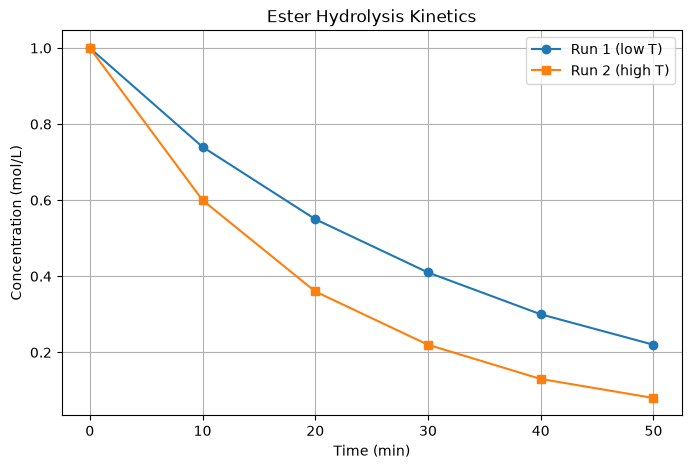


Mean k = mean(P * V) = 4.0240 bar L


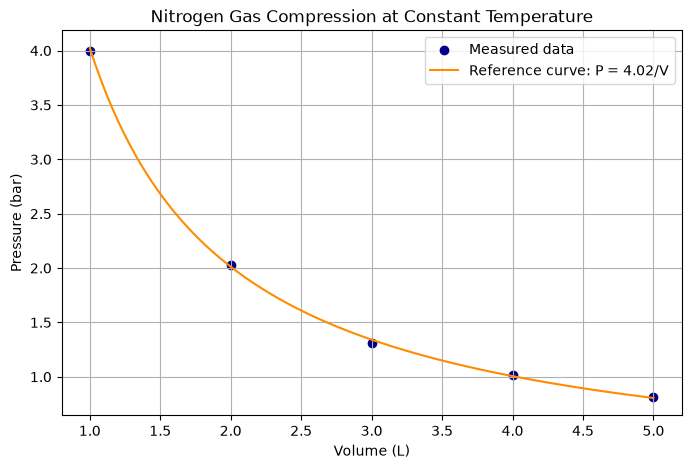

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Ester hydrolysis data
kinetics_df = pd.DataFrame({
    "Time_min": [0, 10, 20, 30, 40, 50],
    "Run1_mol_L": [1.00, 0.74, 0.55, 0.41, 0.30, 0.22],
    "Run2_mol_L": [1.00, 0.60, 0.36, 0.22, 0.13, 0.08],
})

kinetics_df.to_csv("kinetics.csv", index=False)
kinetics_df.to_json("kinetics.json", orient="records", indent=2)

kinetics_from_csv = pd.read_csv("kinetics.csv")
print("Kinetics CSV shape:", kinetics_from_csv.shape)
print("Kinetics CSV data types:")
print(kinetics_from_csv.dtypes)

run1_mean = kinetics_from_csv["Run1_mol_L"].mean()
run1_std = kinetics_from_csv["Run1_mol_L"].std()
run2_mean = kinetics_from_csv["Run2_mol_L"].mean()
run2_std = kinetics_from_csv["Run2_mol_L"].std()

print(f"\nRun 1 mean = {run1_mean:.4f}, standard deviation = {run1_std:.4f}")
print(f"Run 2 mean = {run2_mean:.4f}, standard deviation = {run2_std:.4f}")

if run1_std > run2_std:
    print("Run 1 shows more variation.")
elif run2_std > run1_std:
    print("Run 2 shows more variation.")
else:
    print("Both runs show the same variation.")

plt.figure(figsize=(8, 5))
plt.plot(kinetics_from_csv["Time_min"], kinetics_from_csv["Run1_mol_L"], "o-", label="Run 1 (low T)")
plt.plot(kinetics_from_csv["Time_min"], kinetics_from_csv["Run2_mol_L"], "s-", label="Run 2 (high T)")
plt.title("Ester Hydrolysis Kinetics")
plt.xlabel("Time (min)")
plt.ylabel("Concentration (mol/L)")
plt.legend()
plt.grid(True)
plt.show()

# Nitrogen gas pressure-volume data
pv_df = pd.DataFrame({
    "Volume_L": [1, 2, 3, 4, 5],
    "Pressure_bar": [4.00, 2.03, 1.31, 1.02, 0.81],
})

pv_df["P_times_V"] = pv_df["Pressure_bar"] * pv_df["Volume_L"]
k_pv = pv_df["P_times_V"].mean()
volume_curve = np.linspace(pv_df["Volume_L"].min(), pv_df["Volume_L"].max(), 200)
pressure_curve = k_pv / volume_curve

print(f"\nMean k = mean(P * V) = {k_pv:.4f} bar L")

plt.figure(figsize=(8, 5))
plt.scatter(pv_df["Volume_L"], pv_df["Pressure_bar"], color="darkblue", label="Measured data")
plt.plot(volume_curve, pressure_curve, color="darkorange", label=f"Reference curve: P = {k_pv:.2f}/V")
plt.title("Nitrogen Gas Compression at Constant Temperature")
plt.xlabel("Volume (L)")
plt.ylabel("Pressure (bar)")
plt.legend()
plt.grid(True)
plt.show()
